# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Tota Ram
- **Student ID:** 023-24-0244
- **Section:** G
- **GitHub:** https://github.com/totaramrathore/machine_learning_practical  
- **Kaggle:** https://www.kaggle.com/totaramsarangani/competitions  
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine




## Before You Start

- This is an unsupervised learning task: the Mall dataset has no target column.
- We do not use train/test split or accuracy for Mall clustering.
- Use `SEED = 42`.
- Run cells from top to bottom.

## Part 0 — Setup and First Look

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
print("Libraries imported successfully!")

Libraries imported successfully!


### Task 0.1 — Load and check the data

In [ ]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

required = {"CustomerID", "Gender", "Age", "Income", "Spending"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nGender counts:")
display(df["Gender"].value_counts().to_frame("Count"))
print("\nStatistical summary:")
display(df[["Age", "Income", "Spending"]].describe())

Dataset shape: (200, 5)

Missing values:


,Missing values
CustomerID,0
Gender,0
Age,0
Income,0
Spending,0



Duplicate rows: 0

Gender counts:


,Count
Gender,
Female,112
Male,88



Statistical summary:


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


**Interpretation:** Check the shape, missing-value counts, duplicates and gender counts above. The descriptive statistics show the ranges and typical values of Age, Income and Spending. No target column is available, so this is an unsupervised clustering problem.

### Task 0.2 — Look at the data before clustering

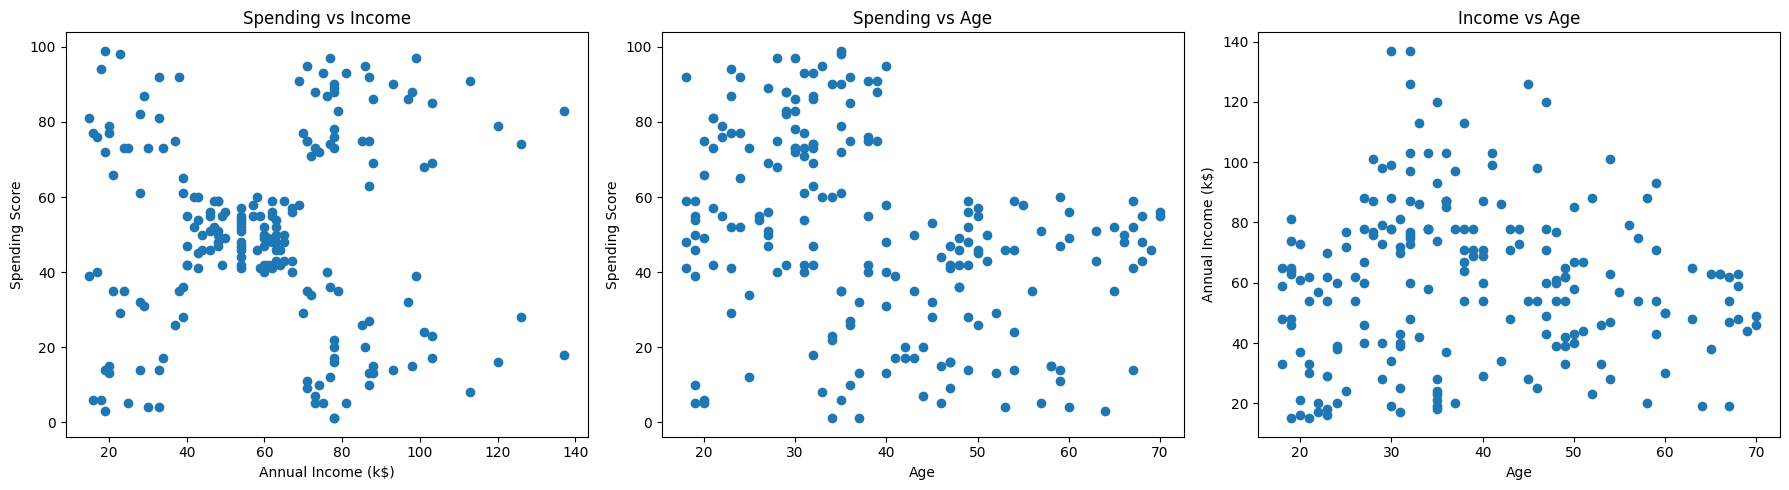

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df["Income"], df["Spending"])
axes[0].set(title="Spending vs Income", xlabel="Annual Income (k$)", ylabel="Spending Score")

axes[1].scatter(df["Age"], df["Spending"])
axes[1].set(title="Spending vs Age", xlabel="Age", ylabel="Spending Score")

axes[2].scatter(df["Age"], df["Income"])
axes[2].set(title="Income vs Age", xlabel="Age", ylabel="Annual Income (k$)")

plt.tight_layout()
plt.show()

**Questions — answers**

- **(a)** Spending vs Income generally shows the clearest visible grouping; Spending vs Age and Income vs Age tend to show less distinct separation. The exact visual impression should be checked against the plots.
- **(b)** Accuracy and a normal train/test split require known target labels. Mall Customers has no true cluster labels, so we assess clustering with distances, silhouette, plots and domain sense.
- **(c)** A feature is an input column describing a row, such as Age, Income or Spending.
- **(d)** A cluster is a group of data points that are close to one another under the chosen distance measure.

## Part 1 — K-Means From Scratch

### Task 1.1 — Lecture Example 1 in code (one feature)

In [ ]:
numbers = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids = np.array([4.0, 11.0])
iteration = 0

while True:
    iteration += 1
    distances = np.abs(numbers[:, None] - centroids[None, :])
    labels = distances.argmin(axis=1)

    new_centroids = centroids.copy()
    for k in range(2):
        if np.any(labels == k):
            new_centroids[k] = numbers[labels == k].mean()

    print(f"Iteration {iteration}")
    for k in range(2):
        print(f"  Cluster C{k+1}:", numbers[labels == k].astype(int).tolist())
    print("  New centroids:", new_centroids)

    if np.allclose(new_centroids, centroids):
        centroids = new_centroids
        break
    centroids = new_centroids

final_labels = np.abs(numbers[:, None] - centroids[None, :]).argmin(axis=1)
inertia_1d = np.sum((numbers - centroids[final_labels]) ** 2)
print("\nFinal centroids:", centroids)
print("Final inertia:", inertia_1d)
print("Iterations:", iteration)

Iteration 1
  Cluster C1: [2, 4, 3]
  Cluster C2: [10, 12, 20, 30, 11, 25]
  New centroids: [ 3. 18.]
Iteration 2
  Cluster C1: [2, 4, 10, 3]
  Cluster C2: [12, 20, 30, 11, 25]
  New centroids: [ 4.75 19.6 ]
Iteration 3
  Cluster C1: [2, 4, 10, 12, 3, 11]
  Cluster C2: [20, 30, 25]
  New centroids: [ 7. 25.]
Iteration 4
  Cluster C1: [2, 4, 10, 12, 3, 11]
  Cluster C2: [20, 30, 25]
  New centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Final inertia: 150.0
Iterations: 4


**Interpretation:** The final centroids should be 7 and 25, and the inertia should be 150, matching the lecture example.

### Task 1.2 — Lecture Example 2 in code (two features)

In [ ]:
X_height_weight = np.array([
    [185, 72], [170, 56], [168, 60],
    [179, 68], [182, 72], [188, 77]
], dtype=float)

C = X_height_weight[[0, 1]].copy()
iteration = 0

while True:
    iteration += 1
    dist = np.sqrt(((X_height_weight[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels_hw = dist.argmin(axis=1)

    new_C = C.copy()
    for k in range(2):
        if np.any(labels_hw == k):
            new_C[k] = X_height_weight[labels_hw == k].mean(axis=0)

    print(f"\nIteration {iteration}")
    for k in range(2):
        print(f"Cluster C{k+1}:")
        for i in np.where(labels_hw == k)[0]:
            print(f"  P{i+1}: {X_height_weight[i]}")
    print("New centroids:\n", new_C)

    if np.allclose(new_C, C):
        C = new_C
        break
    C = new_C

final_dist_hw = np.sqrt(((X_height_weight[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
print("\nFinal distance table:\n", np.round(final_dist_hw, 2))
print("Final centroids:\n", C)
print("First-iteration distance d(P3, M2) should be sqrt(53) ≈", round(np.sqrt(53), 2))


Iteration 1
Cluster C1:
  P1: [185.  72.]
  P4: [179.  68.]
  P5: [182.  72.]
  P6: [188.  77.]
Cluster C2:
  P2: [170.  56.]
  P3: [168.  60.]
New centroids:
 [[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster C1:
  P1: [185.  72.]
  P4: [179.  68.]
  P5: [182.  72.]
  P6: [188.  77.]
Cluster C2:
  P2: [170.  56.]
  P3: [168.  60.]
New centroids:
 [[183.5   72.25]
 [169.    58.  ]]

Final distance table:
 [[ 1.52 21.26]
 [21.13  2.24]
 [19.76  2.24]
 [ 6.19 14.14]
 [ 1.52 19.1 ]
 [ 6.54 26.87]]
Final centroids:
 [[183.5   72.25]
 [169.    58.  ]]
First-iteration distance d(P3, M2) should be sqrt(53) ≈ 7.28


### Task 1.3 — Write your own K-Means function

In [ ]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()
    iterations = 0

    for _ in range(max_iter):
        iterations += 1
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()
        for k in range(len(centroids)):
            # If a cluster is empty, retain its previous centroid.
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break
        centroids = new_centroids

    distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
    labels = distances.argmin(axis=1)
    inertia = np.sum((X - centroids[labels]) ** 2)
    return labels, centroids, inertia, iterations

In [ ]:
X1 = np.array([[2], [4], [10], [12], [3], [20], [30], [11], [25]], dtype=float)
initial = np.array([[4], [11]], dtype=float)

labels_1, centers_1, inertia_1, iterations_1 = my_kmeans(X1, initial)
print("Labels:", labels_1)
print("Final centroids:", centers_1.ravel())
print("Inertia:", inertia_1)
print("Iterations:", iterations_1)

Labels: [0 0 0 0 0 1 1 0 1]
Final centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

In [ ]:
X2 = df[["Income", "Spending"]].to_numpy(dtype=float)
initial_centroids = X2[:5].copy()

my_labels, my_centers, my_inertia, my_iterations = my_kmeans(X2, initial_centroids)

sk_model = KMeans(
    n_clusters=5, init=initial_centroids, n_init=1,
    tol=0, algorithm="lloyd", random_state=SEED
)
sk_model.fit(X2)

print("My K-Means — iterations:", my_iterations, "inertia:", my_inertia)
print("Scikit-learn — iterations:", sk_model.n_iter_, "inertia:", sk_model.inertia_)
print("Centroids match:", np.allclose(my_centers, sk_model.cluster_centers_))
print("Inertia match:", np.isclose(my_inertia, sk_model.inertia_))
print("Labels match directly:", np.array_equal(my_labels, sk_model.labels_))
print("Adjusted Rand Index:", adjusted_rand_score(my_labels, sk_model.labels_))

My K-Means — iterations: 4 inertia: 44448.45544793371
Scikit-learn — iterations: 4 inertia: 44448.4554479337
Centroids match: True
Inertia match: True
Labels match directly: True
Adjusted Rand Index: 1.0


**Questions — answers**

- **(a)** A point can change cluster after centroids move. It is assigned to whichever updated centroid is nearer in that iteration.
- **(b)** The loop stops when centroids no longer move (within the `np.allclose` tolerance) or when `max_iter` is reached. This is convergence to a local solution, not a guarantee of the global best solution.
- **(c)** Compare the printed checks. Cluster IDs can be permuted, so ARI is a better grouping comparison than direct label equality. Small differences may arise from stopping/tie-handling details.
- **(d)** A centroid is the mean feature vector of the customers in a cluster. K-Means needs numeric features because it calculates means and distances.

## Part 2 — Choosing K: Elbow and Silhouette

### Task 2.1 — Elbow and silhouette for K = 2 to 10

,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


K with highest silhouette: 5


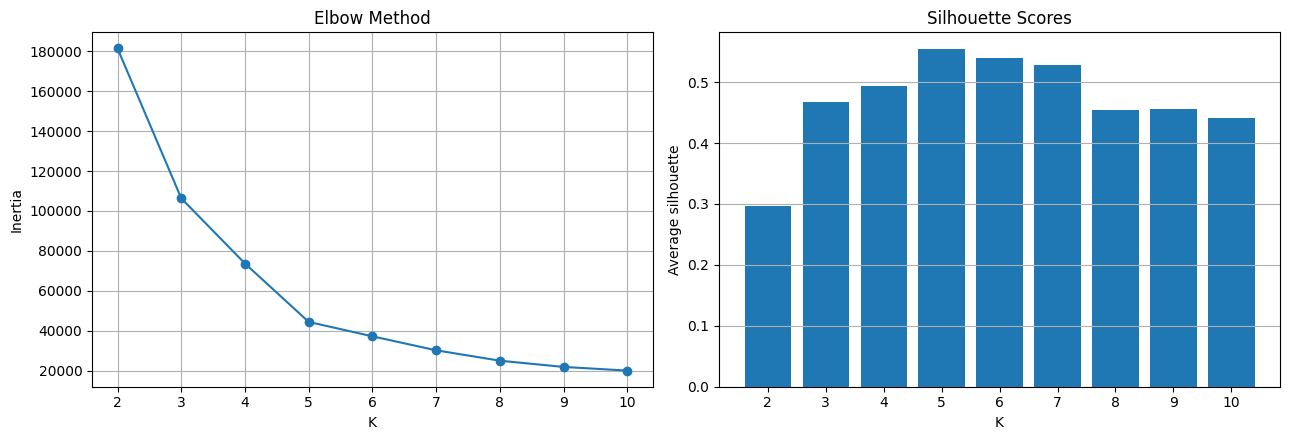

In [ ]:
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels_k = model.fit_predict(X2)
    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X2, labels_k)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))
best_k = int(results_df.loc[results_df["Silhouette"].idxmax(), "K"])
print("K with highest silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(results_df["K"], results_df["Inertia"], marker="o")
axes[0].set(title="Elbow Method", xlabel="K", ylabel="Inertia")
axes[0].set_xticks(range(2, 11))
axes[0].grid(True)

axes[1].bar(results_df["K"], results_df["Silhouette"])
axes[1].set(title="Silhouette Scores", xlabel="K", ylabel="Average silhouette")
axes[1].set_xticks(range(2, 11))
axes[1].grid(axis="y")
plt.tight_layout()
plt.show()

**Interpretation:** The elbow candidate is where the inertia reduction begins to flatten. The silhouette candidate is the K with the highest average silhouette. Use both, plus whether the resulting segments are understandable, rather than relying on one metric alone.

### Task 2.2 — Silhouette by hand

Customer 1: a = 24.64044215163639 b = 42.26526678748377 manual silhouette = 0.41700493041881637
Scikit-learn silhouette = 0.4170049304188163
Match: True


,Cluster,Count,Mean silhouette,Minimum silhouette
0,0,81,0.5967,0.1153
1,1,39,0.5092,0.2254
2,2,22,0.5990,0.0507
3,3,35,0.5040,-0.0234
4,4,23,0.5123,-0.0093


Customers with negative silhouette: 2


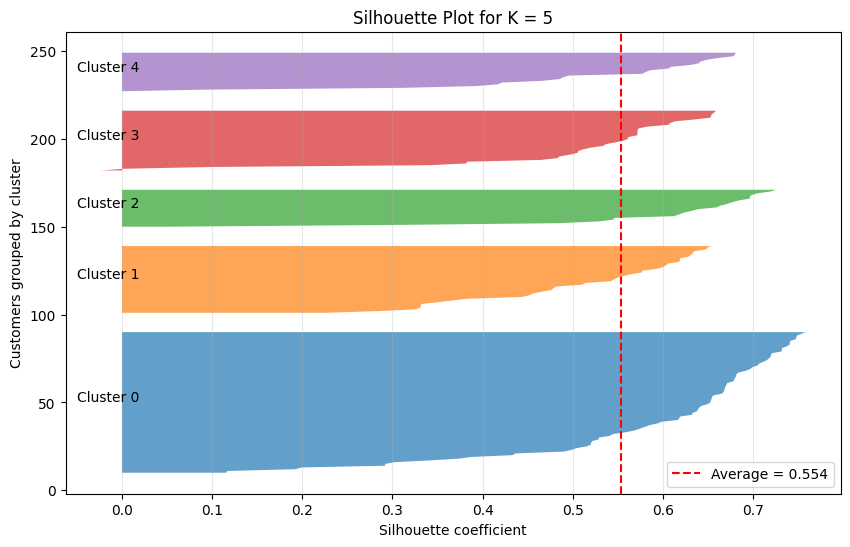

In [ ]:
kmeans5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = kmeans5.fit_predict(X2)

def manual_silhouette(X, labels, point_index):
    X = np.asarray(X, dtype=float)
    point = X[point_index]
    distances = np.sqrt(((X - point) ** 2).sum(axis=1))
    own_cluster = labels[point_index]

    same = labels == own_cluster
    same[point_index] = False
    if not np.any(same):  # silhouette for a singleton cluster
        return 0.0, np.nan, 0.0

    a = distances[same].mean()
    other_means = [
        distances[labels == cluster].mean()
        for cluster in np.unique(labels)
        if cluster != own_cluster and np.any(labels == cluster)
    ]
    b = min(other_means)
    s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
    return a, b, s

a, b, s = manual_silhouette(X2, labels5, 0)
sil_values = silhouette_samples(X2, labels5)
print("Customer 1: a =", a, "b =", b, "manual silhouette =", s)
print("Scikit-learn silhouette =", sil_values[0])
print("Match:", np.isclose(s, sil_values[0]))

cluster_stats = []
for cluster in np.unique(labels5):
    vals = sil_values[labels5 == cluster]
    cluster_stats.append({
        "Cluster": cluster,
        "Count": len(vals),
        "Mean silhouette": vals.mean(),
        "Minimum silhouette": vals.min()
    })
cluster_stats_df = pd.DataFrame(cluster_stats)
display(cluster_stats_df.round(4))
negative_count = int(np.sum(sil_values < 0))
print("Customers with negative silhouette:", negative_count)

plt.figure(figsize=(10, 6))
y_lower = 10
for cluster in np.unique(labels5):
    vals = np.sort(sil_values[labels5 == cluster])
    y_upper = y_lower + len(vals)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7)
    plt.text(-0.05, y_lower + len(vals) / 2, f"Cluster {cluster}")
    y_lower = y_upper + 10

avg_sil = silhouette_score(X2, labels5)
plt.axvline(avg_sil, color="red", linestyle="--", label=f"Average = {avg_sil:.3f}")
plt.xlabel("Silhouette coefficient")
plt.ylabel("Customers grouped by cluster")
plt.title("Silhouette Plot for K = 5")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.show()

### Task 2.3 — The lecture practice problem

In [ ]:
X_practice = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float).reshape(-1, 1)
initial_practice = np.array([[1], [11]], dtype=float)

practice_labels, practice_centroids, practice_inertia, practice_iterations = my_kmeans(
    X_practice, initial_practice
)

print("Final clusters:")
for k in range(2):
    print(f"Cluster {k+1}:", X_practice[practice_labels == k].ravel())
print("Centroids:", practice_centroids.ravel())
print("Iterations:", practice_iterations)
print("Inertia:", practice_inertia)

practice_sil = silhouette_samples(X_practice, practice_labels)
for point in [1, 7, 11]:
    idx = int(np.where(X_practice.ravel() == point)[0][0])
    a, b, manual_s = manual_silhouette(X_practice, practice_labels, idx)
    print(f"Point {point}: a={a:.4f}, b={b:.4f}, manual={manual_s:.4f}, sklearn={practice_sil[idx]:.4f}")

Final clusters:
Cluster 1: [1. 3. 5. 7.]
Cluster 2: [11. 13. 15.]
Centroids: [ 4. 13.]
Iterations: 3
Inertia: 28.0
Point 1: a=4.0000, b=12.0000, manual=0.6667, sklearn=0.6667
Point 7: a=4.0000, b=6.0000, manual=0.3333, sklearn=0.3333
Point 11: a=3.0000, b=7.0000, manual=0.5714, sklearn=0.5714


**Questions — answers**

- **(a)** Read the elbow candidate from the inertia plot and the silhouette candidate from the printed `best_k`. Quote the corresponding inertia drops using `results_df`; the best silhouette K is printed by the notebook.
- **(b)** Customer 1's silhouette is printed above. The lowest mean-silhouette cluster is the weakest; the notebook also prints the number of negative silhouettes.
- **(c)** Point 7 is less well placed in the practice example: its silhouette is lower than point 1's because it is relatively closer to the neighboring cluster.
- **(d)** Inertia cannot select K by itself because it never increases when K is increased; choosing the lowest value would tend toward too many clusters.

## Part 3 — Starting Points and Stability

### Task 3.1 — 30 different seeds

,Setting,Distinct inertia values (1 dp),Lowest inertia,Highest inertia,Runs at best inertia (%)
0,"Random, n_init=1",14,44448.455,91761.976,33.333
1,"K-Means++, n_init=1",6,44448.455,66733.439,60.000
2,"K-Means++, n_init=10",1,44448.455,44448.455,100.000


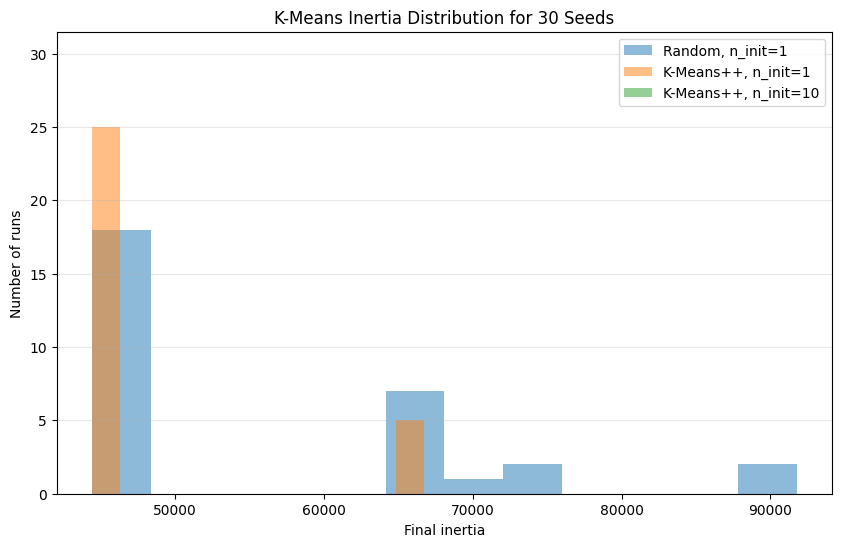

In [ ]:
K = 5
settings = [
    ("Random, n_init=1", "random", 1),
    ("K-Means++, n_init=1", "k-means++", 1),
    ("K-Means++, n_init=10", "k-means++", 10)
]
all_results = {}

for setting_name, init_method, n_init_value in settings:
    runs = []
    for seed in range(30):
        model = KMeans(
            n_clusters=K, init=init_method, n_init=n_init_value,
            random_state=seed
        )
        labels = model.fit_predict(X2)
        runs.append({
            "seed": seed,
            "inertia": model.inertia_,
            "labels": labels.copy(),
            "centroids": model.cluster_centers_.copy()
        })
    all_results[setting_name] = runs

summary = []
for setting_name, runs in all_results.items():
    inertias = np.array([r["inertia"] for r in runs])
    rounded = np.round(inertias, 1)
    best = rounded.min()
    summary.append({
        "Setting": setting_name,
        "Distinct inertia values (1 dp)": len(np.unique(rounded)),
        "Lowest inertia": inertias.min(),
        "Highest inertia": inertias.max(),
        "Runs at best inertia (%)": np.mean(rounded == best) * 100
    })

summary_df = pd.DataFrame(summary)
display(summary_df.round(3))

plt.figure(figsize=(10, 6))
for setting_name, runs in all_results.items():
    plt.hist([r["inertia"] for r in runs], bins=12, alpha=0.5, label=setting_name)
plt.xlabel("Final inertia")
plt.ylabel("Number of runs")
plt.title("K-Means Inertia Distribution for 30 Seeds")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

### Task 3.2 — Best run vs worst run

Best run — seed: 0 inertia: 44448.4554479337
Worst run — seed: 13 inertia: 91761.97619211904
ARI between best and worst: 0.45525713010305063


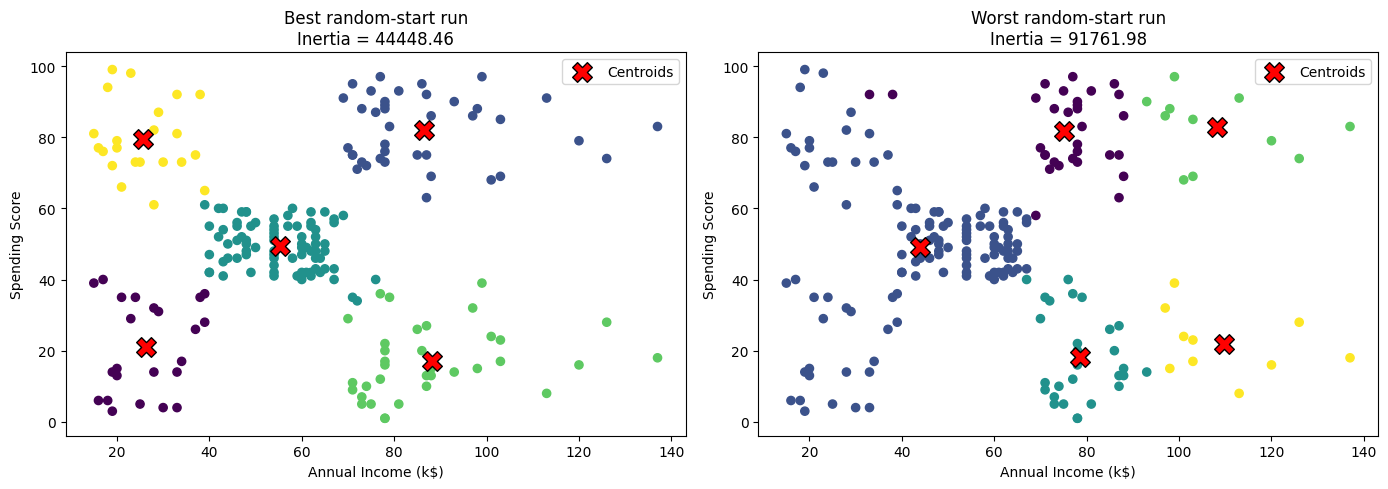

In [ ]:
random_runs = all_results["Random, n_init=1"]
best_run = min(random_runs, key=lambda r: r["inertia"])
worst_run = max(random_runs, key=lambda r: r["inertia"])

print("Best run — seed:", best_run["seed"], "inertia:", best_run["inertia"])
print("Worst run — seed:", worst_run["seed"], "inertia:", worst_run["inertia"])
print("ARI between best and worst:", adjusted_rand_score(best_run["labels"], worst_run["labels"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, run, title in [
    (axes[0], best_run, "Best random-start run"),
    (axes[1], worst_run, "Worst random-start run")
]:
    ax.scatter(X2[:, 0], X2[:, 1], c=run["labels"], cmap="viridis", s=35)
    ax.scatter(run["centroids"][:, 0], run["centroids"][:, 1],
               marker="X", s=200, color="red", edgecolor="black", label="Centroids")
    ax.set(title=f"{title}\nInertia = {run['inertia']:.2f}",
           xlabel="Annual Income (k$)", ylabel="Spending Score")
    ax.legend()
plt.tight_layout()
plt.show()

**Questions — answers**

- **(a)** Use the comparison table: it reports the distinct rounded inertia values and percentage of runs reaching the best rounded inertia for all three settings.
- **(b)** Different initial centroids can lead the assign/update loop to different local minima.
- **(c)** K-Means++ spreads initial centers more intelligently; `n_init=10` tries ten starts and retains the lowest-inertia solution. The exact result is in the table.
- **(d)** Cluster IDs are arbitrary. ARI compares membership/grouping and is unaffected by renumbering cluster labels.

## Part 4 — Scaling: Units Decide the Clusters

### Task 4.1 — Change the unit, change the clusters

ARI raw k$ vs raw dollars: 0.48965682118947657
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled: 0.36045266264603926


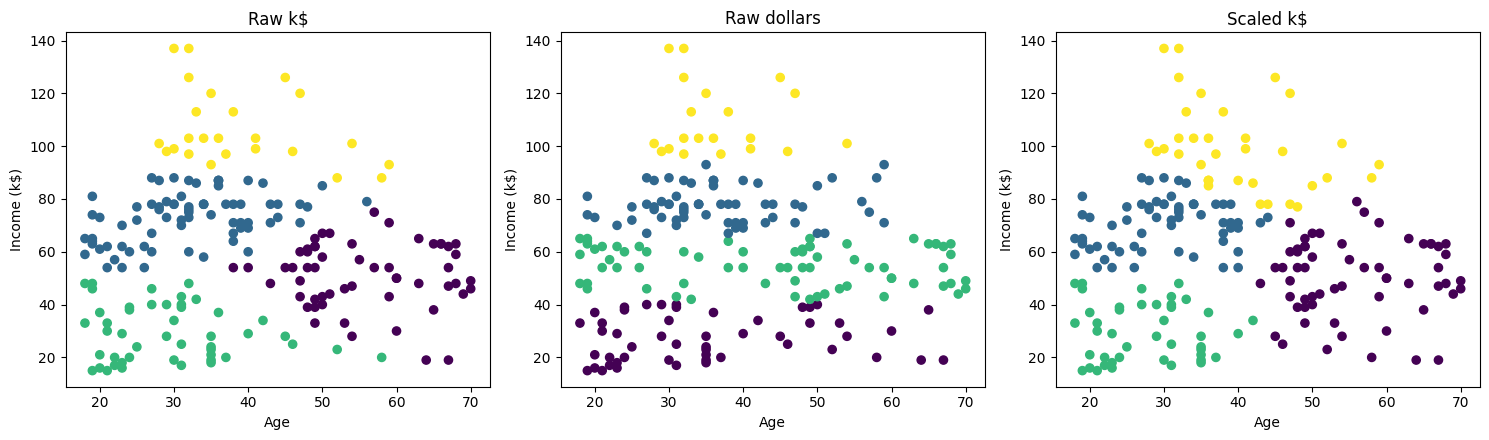

In [ ]:
X_age_income = df[["Age", "Income"]].to_numpy(dtype=float)
X_age_income_dollars = X_age_income.copy()
X_age_income_dollars[:, 1] *= 1000

def fit_kmeans_labels(X):
    model = KMeans(n_clusters=4, n_init=10, random_state=SEED)
    labels = model.fit_predict(X)
    return model, labels

raw_k_model, raw_k_labels = fit_kmeans_labels(X_age_income)
raw_dollar_model, raw_dollar_labels = fit_kmeans_labels(X_age_income_dollars)

scaled_k = StandardScaler().fit_transform(X_age_income)
scaled_dollar = StandardScaler().fit_transform(X_age_income_dollars)
scaled_k_model, scaled_k_labels = fit_kmeans_labels(scaled_k)
scaled_dollar_model, scaled_dollar_labels = fit_kmeans_labels(scaled_dollar)

print("ARI raw k$ vs raw dollars:", adjusted_rand_score(raw_k_labels, raw_dollar_labels))
print("ARI scaled k$ vs scaled dollars:", adjusted_rand_score(scaled_k_labels, scaled_dollar_labels))
print("ARI raw dollars vs scaled:", adjusted_rand_score(raw_dollar_labels, scaled_dollar_labels))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_items = [
    (raw_k_labels, "Raw k$"),
    (raw_dollar_labels, "Raw dollars"),
    (scaled_k_labels, "Scaled k$")
]
for ax, (labels, title) in zip(axes, plot_items):
    ax.scatter(df["Age"], df["Income"], c=labels, cmap="viridis", s=35)
    ax.set(title=title, xlabel="Age", ylabel="Income (k$)")
plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

In [ ]:
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
wine_feature_names = wine.feature_names

wine_std = pd.Series(X_wine.std(axis=0), index=wine_feature_names).sort_values(ascending=False)
print("Three largest feature standard deviations:")
display(wine_std.head(3).to_frame("Standard deviation"))
print("Smallest feature standard deviation:")
display(wine_std.tail(1).to_frame("Standard deviation"))

wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

wine_raw_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
wine_raw_labels = wine_raw_model.fit_predict(X_wine)

wine_scaled_model = KMeans(n_clusters=3, n_init=10, random_state=SEED)
wine_scaled_labels = wine_scaled_model.fit_predict(X_wine_scaled)

print("RAW WINE")
print("ARI vs true cultivars:", adjusted_rand_score(y_wine, wine_raw_labels))
print("Silhouette:", silhouette_score(X_wine, wine_raw_labels))
print("Cluster sizes:", np.bincount(wine_raw_labels))

print("\nSCALED WINE")
print("ARI vs true cultivars:", adjusted_rand_score(y_wine, wine_scaled_labels))
print("Silhouette:", silhouette_score(X_wine_scaled, wine_scaled_labels))
print("Cluster sizes:", np.bincount(wine_scaled_labels))

Three largest feature standard deviations:


,Standard deviation
proline,314.021657
magnesium,14.242308
alcalinity_of_ash,3.330170


Smallest feature standard deviation:


,Standard deviation
nonflavanoid_phenols,0.124103


RAW WINE
ARI vs true cultivars: 0.37111371823084754
Silhouette: 0.5711381937868838
Cluster sizes: [62 47 69]

SCALED WINE
ARI vs true cultivars: 0.8974949815093207
Silhouette: 0.2848589191898987
Cluster sizes: [65 51 62]


### Task 4.3 — PCA view: true cultivars, raw clusters, scaled clusters

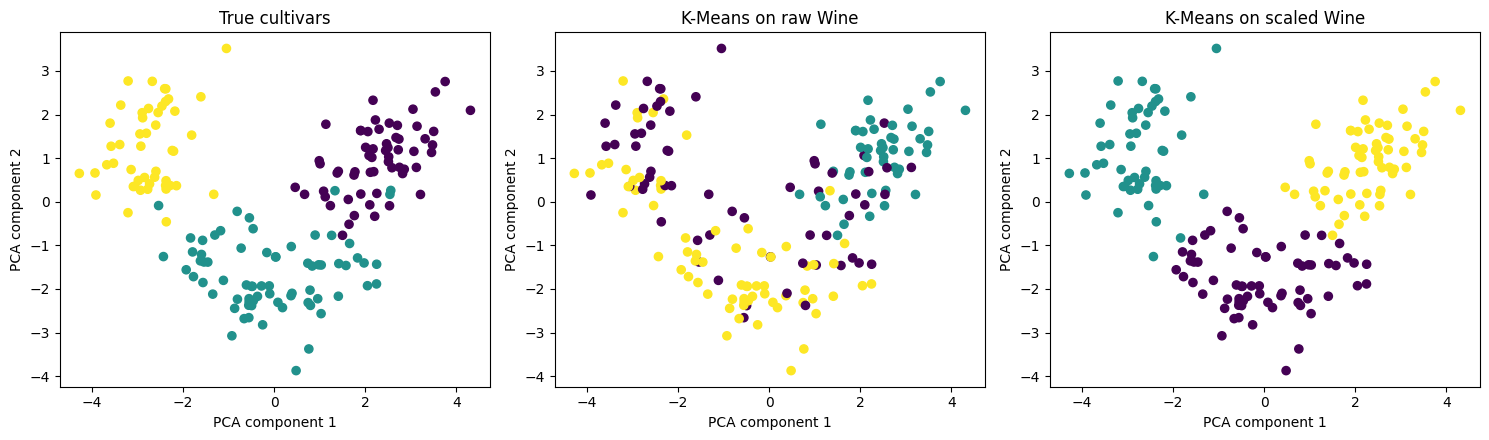

Explained variance ratio: [0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693526


In [ ]:
# Fit one PCA transformation on scaled Wine data and use the same coordinates in all plots.
pca = PCA(n_components=2, random_state=SEED)
wine_pca = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
views = [
    (y_wine, "True cultivars"),
    (wine_raw_labels, "K-Means on raw Wine"),
    (wine_scaled_labels, "K-Means on scaled Wine")
]
for ax, (labels, title) in zip(axes, views):
    ax.scatter(wine_pca[:, 0], wine_pca[:, 1], c=labels, cmap="viridis", s=35)
    ax.set_title(title)
    ax.set_xlabel("PCA component 1")
    ax.set_ylabel("PCA component 2")
plt.tight_layout()
plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

**Questions — answers**

- **(a)** Multiplying Income by 1000 makes its squared difference in Euclidean distance 1,000,000 times larger. Income therefore dominates the unscaled distance and can change the clusters. Standardizing removes this unit change; scaled k$ and scaled dollars should produce the same standardized feature values (up to numerical precision).
- **(b)** The feature with the largest standard deviation, printed in Task 4.2, dominates raw distance most strongly. Compare its standard deviation with the next-largest values and quote the raw and scaled ARI values printed above.
- **(c)** Silhouette measures separation in the particular distance space used; it does not compare clusters with true cultivar labels. A high raw silhouette can coexist with a low ARI. Raw and scaled silhouettes use different distance geometries, so they should not be treated as directly comparable.
- **(d)** Scale when features have different units/ranges and should contribute comparably to distance. Keep original scales only when their relative magnitudes are meaningful for the problem, and check the resulting clusters with domain knowledge.

## Part 5 — Outliers and Anomalies

### Task 5.1 — One extreme customer

Original cluster sizes: [81 39 22 35 23]
With extra customer cluster sizes: [100   1  23  39  38]
ARI on original customers: 0.7532040415286123

Original centroids sorted by Income:


,Income,Spending
0,25.73,79.36
1,26.30,20.91
2,55.30,49.52
3,86.54,82.13
4,88.20,17.11


Centroids with extra customer sorted by Income:


,Income,Spending
0,26.30,20.91
1,48.26,56.48
2,86.54,82.13
3,87.00,18.63
4,400.00,99.00


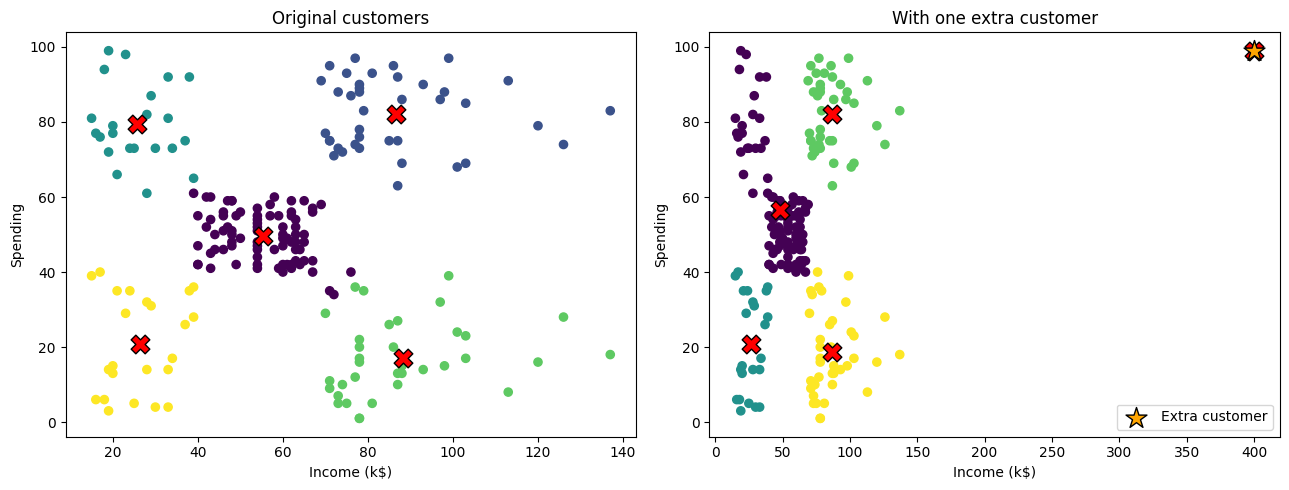

In [ ]:
X2 = df[["Income", "Spending"]].to_numpy(dtype=float)
extra_customer = np.array([[400.0, 99.0]])
X2_with_extra = np.vstack([X2, extra_customer])

original_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
original_labels = original_model.fit_predict(X2)

extra_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
extra_labels_all = extra_model.fit_predict(X2_with_extra)
extra_labels_original = extra_labels_all[:-1]

print("Original cluster sizes:", np.bincount(original_labels))
print("With extra customer cluster sizes:", np.bincount(extra_labels_all))
print("ARI on original customers:", adjusted_rand_score(original_labels, extra_labels_original))

def sorted_centroid_table(model):
    centers = model.cluster_centers_
    order = np.argsort(centers[:, 0])
    return pd.DataFrame(centers[order], columns=["Income", "Spending"])

print("\nOriginal centroids sorted by Income:")
display(sorted_centroid_table(original_model).round(2))
print("Centroids with extra customer sorted by Income:")
display(sorted_centroid_table(extra_model).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=original_labels, cmap="viridis", s=35)
axes[0].scatter(original_model.cluster_centers_[:, 0], original_model.cluster_centers_[:, 1],
                marker="X", s=180, color="red", edgecolor="black")
axes[0].set_title("Original customers")

axes[1].scatter(X2_with_extra[:, 0], X2_with_extra[:, 1], c=extra_labels_all, cmap="viridis", s=35)
axes[1].scatter(extra_model.cluster_centers_[:, 0], extra_model.cluster_centers_[:, 1],
                marker="X", s=180, color="red", edgecolor="black")
axes[1].scatter(400, 99, marker="*", s=250, color="orange", edgecolor="black", label="Extra customer")
axes[1].set_title("With one extra customer")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending")
plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

In [ ]:
# Distances for the original 200 customers, using their original fitted model.
real_distances = original_model.transform(X2).min(axis=1)
threshold = real_distances.mean() + 3 * real_distances.std()
extra_distance = original_model.transform(extra_customer).min(axis=1)[0]
real_flags = real_distances > threshold
extra_flag = extra_distance > threshold

print("Distance threshold (mean + 3 std):", threshold)
print("Real customers flagged:", int(real_flags.sum()))
print("Extra customer's nearest-centroid distance:", extra_distance)
print("Is extra customer flagged?", bool(extra_flag))

distance_table = df[["CustomerID", "Age", "Income", "Spending"]].copy()
distance_table["Cluster"] = original_labels
distance_table["Distance"] = real_distances
print("\nFive real customers farthest from their centroid:")
display(distance_table.nlargest(5, "Distance"))

# Refit after removing flagged real customers, then predict all original customers.
X2_clean = X2[~real_flags]
clean_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
clean_model.fit(X2_clean)
clean_predictions_all = clean_model.predict(X2)

print("Cluster sizes after removing flagged rows (training data):",
      np.bincount(clean_model.labels_, minlength=5))
print("ARI vs original model on all original customers:",
      adjusted_rand_score(original_labels, clean_predictions_all))

Distance threshold (mean + 3 std): 34.80239628396867
Real customers flagged: 4
Extra customer's nearest-centroid distance: 313.9152649312717
Is extra customer flagged? True

Five real customers farthest from their centroid:


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.469069
198,199,32,137,18,3,48.808037
197,198,32,126,74,1,40.289958
196,197,45,126,28,3,39.336227
195,196,35,120,79,1,33.607443


Cluster sizes after removing flagged rows (training data): [80 34 23 37 22]
ARI vs original model on all original customers: 0.9847169139719528


**Questions — answers**

- **(a)** Compare the printed original and with-extra cluster sizes, centroid tables and ARI. The extreme point can pull a centroid toward itself and alter assignments of real customers.
- **(b)** The mean-plus-three-standard-deviations rule flags the extra customer if its nearest-centroid distance exceeds the printed threshold. Real flagged rows should be inspected; they may be valid unusual customers rather than data errors.
- **(c)** Two approaches are to investigate/correct data errors and to use robust methods or treat anomalies separately. Simply deleting outliers risks removing valid, important customers and biasing the analysis.

## Part 6 — From Clusters to Customer Segments

### Task 6.1 — Profile and name the segments

In [ ]:
# Use original customers and K=5 on Income and Spending.
segment_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
segment_labels = segment_model.fit_predict(X2)

seg_df = df.copy()
seg_df["Cluster"] = segment_labels

seg_profile = seg_df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean"),
    Female_Percent=("Gender", lambda x: (x == "Female").mean() * 100)
).sort_values("Mean_Income")
display(seg_profile.round(2))

def level(value, low_cut, high_cut):
    if value < low_cut:
        return "Low"
    if value >= high_cut:
        return "High"
    return "Mid"

def make_segment_name(row):
    income_level = level(row["Income"], 40, 70)
    spending_level = level(row["Spending"], 35, 65)
    return f"{income_level} income / {spending_level} spending"

seg_df["Segment"] = seg_df.apply(make_segment_name, axis=1)
print("Segment sizes:")
display(seg_df["Segment"].value_counts().to_frame("Customers"))

,Customers,Mean_Age,Mean_Income,Mean_Spending,Female_Percent
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


Segment sizes:


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


### Task 6.2 — Does Gender matter? Does Age matter?

In [ ]:
print("Female percentage by segment:")
female_by_segment = pd.crosstab(
    seg_df["Segment"], seg_df["Gender"], normalize="index"
).mul(100)
display(female_by_segment.round(2))

overall_female = (seg_df["Gender"] == "Female").mean() * 100
print(f"Overall female percentage: {overall_female:.2f}%")

X3_raw = df[["Age", "Income", "Spending"]].to_numpy(dtype=float)
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3_raw)

age_sil_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X3_scaled)
    age_sil_results.append({
        "K": k,
        "Silhouette": silhouette_score(X3_scaled, labels)
    })
age_sil_df = pd.DataFrame(age_sil_results)
display(age_sil_df.round(4))
best_k_3features = int(age_sil_df.loc[age_sil_df["Silhouette"].idxmax(), "K"])
print("Best K for scaled Age, Income and Spending:", best_k_3features)

Female percentage by segment:


Gender,Female,Male
Segment,,
High income / High spending,56.76,43.24
High income / Low spending,45.45,54.55
High income / Mid spending,50.00,50.00
Low income / High spending,61.90,38.10
Low income / Low spending,64.71,35.29
Low income / Mid spending,50.00,50.00
Mid income / High spending,0.00,100.00
Mid income / Mid spending,58.44,41.56


Overall female percentage: 56.00%


,K,Silhouette
0,2,0.3355
1,3,0.3578
2,4,0.4040
3,5,0.4166
4,6,0.4284
5,7,0.4172
6,8,0.4082


Best K for scaled Age, Income and Spending: 6


### Task 6.3 — A three-feature alternative

In [ ]:
three_feature_model = KMeans(
    n_clusters=best_k_3features, n_init=10, random_state=SEED
)
three_feature_labels = three_feature_model.fit_predict(X3_scaled)

three_feature_profile = df[["Age", "Income", "Spending"]].copy()
three_feature_profile["Cluster"] = three_feature_labels
profile3 = three_feature_profile.groupby("Cluster").agg(
    Customers=("Age", "size"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
).sort_values("Mean_Age")
display(profile3.round(2))

print("ARI between 2-feature K=5 and 3-feature segmentation:",
      adjusted_rand_score(segment_labels, three_feature_labels))

,Customers,Mean_Age,Mean_Income,Mean_Spending
Cluster,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


ARI between 2-feature K=5 and 3-feature segmentation: 0.7002329184122666


**Questions — answers**

- **(a)** Use the profile table to describe each cluster by its average income and spending. Give it a short name and choose an action that matches that profile; do not infer names from cluster numbers alone.
- **(b)** The most valuable current segment and the biggest opportunity depend on the actual profile values and customer counts. Use the printed table to justify your choice.
- **(c)** Compare each segment's female percentage with the overall female percentage. Large differences may indicate gender composition differences, but do not assume gender caused the clusters.
- **(d)** Adding Age may change assignments; use the three-feature profile and ARI to assess the change. Choose the segmentation that is most interpretable and useful. Silhouette scores from different feature sets are not directly comparable.

## Part 7 — Final Output and Wrap-Up

### Task 7.1 — Save the segments

In [ ]:
# Export one row per original customer with the requested columns.
export_df = seg_df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]].copy()
export_df.to_csv("customer_segments.csv", index=False)

print("Saved customer_segments.csv")
print("Number of customers:", len(export_df))
print("\nCustomers per segment:")
display(export_df["Segment"].value_counts().to_frame("Customers"))

Saved customer_segments.csv
Number of customers: 200

Customers per segment:


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


### Executive Summary

1. This analysis used K-Means to segment Mall customers using Annual Income and Spending Score.
2. Five clusters were used for the business segmentation, and their profiles and sizes are reported in the tables above.
3. Segment names were assigned from income and spending bands so that the groups are understandable to a marketing team.
4. The elbow and silhouette results were examined as evidence when considering the number of clusters.
5. Scaling was tested because distance-based clustering can be dominated by features with larger numeric scales.
6. An extreme customer was added as a sensitivity test, and a distance threshold was used to flag unusual observations.
7. The exported `customer_segments.csv` contains CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
8. A limitation is that K-Means assumes distance-based, roughly compact groups and the Mall dataset has no true labels.

**Final questions — answers**

- **(a)** The most surprising result should be selected from your own outputs; a useful point to discuss is how changing feature units or adding one extreme customer can change distance-based clusters.
- **(b)** With one more hour, I would test additional K values and robust clustering/outlier approaches, then check whether the segments remain stable and useful.

## Final Checklist

- [ ] `Mall_Customers.csv` is in the notebook folder.
- [ ] Run all cells from top to bottom.
- [ ] Review the actual numeric outputs and plots.
- [ ] Check that `customer_segments.csv` was created.
- [ ] Save the completed notebook after execution so outputs are included.